### Introdução e Contextualização do Notebook 03

### Modelagem Preditiva e Mitigação de Risco em AML (Anti-Money Laundering)

### Objetivo do Notebook
Este notebook constitui a terceira etapa do projeto de Ciência de Dados voltado para a prevenção de fraudes e lavagem de dinheiro utilizando o dataset **PaySim** (disponível no Kaggle). O foco central é a transição da análise exploratória de dados (EDA - notebook 02) para a construção, treino, validação e comparação de modelos preditivos de **Machine Learning**.

## Etapa 1: Premissas e Escopo Técnico
1. **Foco Operacional em Transações de Risco:** Conforme validado na EDA, as fraudes no simulador PaySim ocorrem exclusivamente nas modalidades de transferência (`TRANSFER`) e saque (`CASH_OUT`). Outras transações, como pagamentos e depósitos, são estruturalmente legítimas, portanto o escopo analítico é direcionado para isolar e classificar o risco neses dois vetores.
2. **Mitifação de Vazamento de Dados (*Data Leakage*):** O dataset original contém colunas de saldo bruto que carregam o gabarito contábil do simulador. Abordaremos essa vulnerabilidade criando **features** de erro matemático, simulando um ambiente de produção real e defensivo. 
 3. **Métrica de Avaliação de Negócio:** Em sistemas de prevenção a fraude, a minimização de Falsos Negativos (fraudes não detectadas) é prioridade crítica, exigindo o uso estratégico de métricas como **Recall**, curvas de decisão e matrizes de confusão ponderadas.

In [38]:
import sqlite3
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1. Estabelecendo conexão otimizada com o banco de dados SQLite 
DB_FILE = 'paysim_banco.db'
conn = sqlite3.connect(DB_FILE)

print("Carregando dados filtrados do banco para o pipeline de Machine Learning...\n")

# 2. Query SQL direcioanda para extração exclusiva de vetores de risco (TRANSFER e CASH_OUT)
# Essa filtragem reduz a dimensionalidade desnecessária e otimiza o uso de memória RAM.
query_ml = """
SELECT type, amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, isFraud
FROM transacoes
WHERE type IN ('TRANSFER', 'CASH_OUT');
"""

# Carregando o resultado diretamente para um DataFrame do Pandas
df_ml = pd.read_sql_query(query_ml, conn)

# 3. Inspeção inicial da volumetria e do desbalanceamento estrutural da classe alvo
print(f"Total de linhas carregadas para modelagem: {len(df_ml):,}")
print("\nDistribuição da variável alvo (isFraud):")
print(df_ml['isFraud'].value_counts())
print("\nProporção percentual de fraudes na base filtrada:")
print((df_ml['isFraud'].value_counts(normalize=True) * 100).map('{:.4f}%'.format))

Carregando dados filtrados do banco para o pipeline de Machine Learning...

Total de linhas carregadas para modelagem: 2,770,409

Distribuição da variável alvo (isFraud):
isFraud
0    2762196
1       8213
Name: count, dtype: int64

Proporção percentual de fraudes na base filtrada:
isFraud
0    99.7035%
1     0.2965%
Name: proportion, dtype: str


## Análise do Output: Volumetria e Desbalancemento Estrutural

A Execução da carga inicial de dados filtrados nos fornece importantes direções arquiteturais e estatísticas para o o pipeline de modelagem:

### 1. Eficácia da Filtragem de Escopo
* **Volumetria Total:** Foram carregados **2.770.409** registros no DataFrame de trabalho. Esse volume representa com precisão o subconjunto de transações das modalidades `TRANSFER`e `CASH_OUT`, confirmando que foram eliminados os ruídos desnecessários de operações que estruturalmente não possuem histórico de fraude no simulador PaySim.

### 2. Diagnóstisco de Desbalanceamento Severo das Classes
* **Transações Legítimas (Classe `0`):** **2.762.196** ocorrências (~99.70%).
* **Transações Fraudulentas (Classe `1`):** **8.213** ocorrências (~0.30%).

### 3. Implicações Para a Estratégia de Modelagem
A proporção de aproximadamente **1 fraude para cada 330 transações legítimas** evidencia um cenário clássico de **desbalanceamento extremo**.
* **O Risco da Acurácia Ingênua:** Se um modelo simples prever que *todas* as transações são legítimas, ele alcançará uma acurácia matemática de **99.7**, mas falhará em absolutamente 100% das detecções de fraude. 
* **Direcionamento Técnico:** Esse diagnóstico justifica a necessidade de **não** utilizar métricas rasas, como a Acurácia Global, e obriga o uso de técnicas de compensação de pesos, otimização de limiares de decisão (*threshold tuning*) e avaliação focada em **Recall**, **Precision** e **Matriz de Confusão**. 

## Etapa 2: Preparação dos Dados: Codificação Categórica e Divisão Estratificada

Com os dados brutos filtrados, realizamos as transformações necessárias para que os algoritmos matemáticos consigam processar informações corretamente:

### 1. Codificação de Variáveis Categóricas (*One-Hot Encoding*)
* A coluna `type`contém valores textuais (`TRANSFER`e `CASH_OUT`). Como os modelos de *Machine Learning* operam estritamente com números, utilizamos o `pd.get_dummies` para convertê-las em colunas binárias. 
* O parâmetro `drop_first=True` é aplicado para remover uma das colunas resultantes, evitando a **multicolinearidade** (redundância matemática onde uma variável pode ser prevista pelas outras).

### 2. Divisão Estratificada (Train/Test Split com `stratify=y`)
* Em datasets altamente desbalanceados (~0.30% de fraudes), uma divisão aleatória simples corre o risco de deixar o conjunto de teste sem nenhuma fraude ou com uma proporção distorcida.
* O uso de `stratify=y` assegura que a proporção exata da classe minoritária seja copiada identicamente tanto para o conjunto de treino (70%) quanto para o conjunto de teste (30%), garantindo uma avaliação imparcial e estitiscamente robusta. 

In [39]:
# 2. Transformando a coluna categórica 'type' em variáveis númericas (One-Hot Encoding)
df_ml = pd.get_dummies(df_ml, columns=['type'], drop_first=True)

# 3. Separando as Matrizes de Atibutos Preditivos (X) e o Vetor Alvo (y)
X = df_ml.drop(columns=['isFraud'])
y = df_ml['isFraud']

# 4. Dividindo em dados de Treino (70%) e Teste (30%)
# O 'stratify=y' garante que a proporção de fraudes seja mantida identicamente no treino e no teste.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 5. Auditoria volumétrica e conferência de estabilidade da estratificação 
print(f"Dados de Treino: {len(X_train):,} linhas")
print(f"Dados de Teste: {len(X_test):,} linhas")
print(f"\nVolume absoluto de Fraudes no Treino: {y_train.sum():,}")
print(f"Volume absoluto de Fraudes no Teste: {y_test.sum():,}")
print(f"\nTaxa relativa de fraudes no Treino: {(y_train.sum() / len(X_train)) * 100:.4f}%")
print(f"Taxa relativa de fraudes no Teste: {(y_test.sum() / len(X_test)) * 100:.4f}%")

Dados de Treino: 1,939,286 linhas
Dados de Teste: 831,123 linhas

Volume absoluto de Fraudes no Treino: 5,749
Volume absoluto de Fraudes no Teste: 2,464

Taxa relativa de fraudes no Treino: 0.2964%
Taxa relativa de fraudes no Teste: 0.2965%


### Análise e Validação do Particionamento Amostral (Treino/Teste)

A auditoria dos dados resultantes do particionamento e da codificação categórica confirma a perfeita aplicação do critério de **Amostragem Estratificada (`stratify=y`)**:

#### 1. Mapeamento da Proporção Preditiva
* **Base de Treino (70%):** **1.939.286** linhas, contendo **5.749** transações fraudulentas registradas.
* **Base de Teste (30%):** **831.123** linhas, contendo **2.464** transações fraudulentas registradas.

#### 2. Rigor Estatístico da Estratificação
* **Taxa de Fraudes no Treino:** **0.2964%**
* **Taxa de Fraudes no Teste:** **0.2965%**

A diferença irrisória de *0,0001%* na proporção da classe alvo entre os conjuntos valida que o ecossistema de avaliação é uma réplica estatiscamente fiel da base original. Essa garantia impede a ocorrência de *sampling bias* (viés de amostragem), assegurando que o desempenho que o modelo apresentar na fase de testes refletirá a sua real capacidade de generalização em ambiente de produção real. 

## Etapa 3: Modelo Baseline e a Armadilha do Data Leakage (*vazamento de dados*)

Antes de aplicar qualquer engenharia de mitigação ou alteração estrutural, é fundamental estabelecer um modelo de referência (*baseline*). Para isso, treinaremos uma **Regressão Logística** padrão utilizando todas as colunas originais do dataset na íntegra - incluindo as variáveis de saldo bruto (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest` e `newbalanceDest`).

### O Conceito Crítico de *Data Leakage* (vazamento de dados)
No simulador PaySim, as colunas de salto contêm a regra matemática exata gerada pelo sistema para registrar a movimentação financeira. Quando alimentamos um algoritmo com essa variáveis brutas, o modelo não aprende padrões comportamentais reais de fraude; ele "pesca" a identidade matemática direta do simulador (a fórmula contábil interna), gerando uma falsa sensação de desempenho perfeito. 

In [40]:
# Passo 1: Treinando o Modelo Baseline com os Dados Brutos (Contendo Vazamento Estrutural)
print("Treinando o modelo baseline com os dados crus...")

# Instanciando e treinando a Regressão Logística
# Utilizaremos max_inter=1000 para assegurar a convergência adequada com a volumetria da base 
model_baseline = LogisticRegression(max_iter=1000, random_state=42)
model_baseline.fit(X_train, y_train)

# Realizando previsões no conjunto de teste estritamente isolado
y_pred_baseline = model_baseline.predict(X_test)

# Avaliação quantitativa dos resultados iniciais da baseline
print("\n--- MATRIZ DE CONFUSÃO (BASELINE) ---")
print(confusion_matrix(y_test, y_pred_baseline))

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO ---")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

Treinando o modelo baseline com os dados crus...

--- MATRIZ DE CONFUSÃO (BASELINE) ---
[[828548    111]
 [  1330   1134]]

--- RELATÓRIO DE CLASSIFICAÇÃO ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    828659
           1       0.91      0.46      0.61      2464

    accuracy                           1.00    831123
   macro avg       0.95      0.73      0.81    831123
weighted avg       1.00      1.00      1.00    831123



## Análise do Diagnóstico do *Data Leakage* no Baseline

Os números apresentados pela Regressão Logística treinada com os dados brutos revelam um comportamento clássico de **Data Leakage (vazamento de dados)**  mascarado por limitações lineares:

#### 1. Desconstrução da Matriz de Confusão e Métricas
* **Acurácia Global (1.00) e Precisão de Fraude (0.91):** Em um cenário de desbalanceamento severo, onde as fraudes representam apenas 0,3% da base, obter uma precisão de 91% na classes minoritárias é um indicador anômalo. Significa que quando o modelo aponta uma fraude, ele acerta na esmagadora maioria das vezes.
* **O Calcanhar de Aquiles (Recall = 0.46):** Apesar da alta precisão, o modelo deixou escapar mais da metade das fraudes reais, ou seja, 1.330 falsos negativos, capturando apenas 46% do total. Isso ocorre porque a Regressão Logística é um modelo linear e não consegue desenhar fronteiras de decisão complexas o suficiente para capturar todas as regras lógicas ocultas do simulador PaySim.

#### 2. A Prova do Crime: Por que isso aponta *Data Leakage*?
O modelo conseguiu uma precisão de 91% sem nenhum ajuste prévio devido as colunas de saldo bruto (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) possuírem a **fórmula matemática determinística** utilizada pelo criador do PaySim para gerar as transações fraudulentas.
* O algoritmo não aprendeu a identificar o *comportamento* de um fraudador; ele simplesmente "pescou" a identidade matemática direta do simulador. 
* Em um ambiente de produção real, um sistema antifraude não pode depender de saldos futuros ou de campos manipulados diretamente pela regra de geração do sistema.

#### 3. Próximo Passo Estrutural
Para construir um modelo legítimo, defensivo e utilizável no mercado de trabalho, **precisamos remover as colunas de saldo bruto** e substituí-las por *features* de engenharia de erro contábil (`erro_origem` e `erro_destino`), forçando o algoritmo a aprender padrões reais de inconsistência financeira e não atalhos matemáticos artificiais. 

# Etapa 4: Engenharia de Erro Contábil e Limpeza de Vazamento de Dados 

#### A Lógica por trás da Nova Engenharia de Recursos 
Para eliminar o *Data Leakage* sem perder a riqueza informacional que os saldos oferecem, transformamos as variáveis absolutas em **indicadores de discrepância matemática (erros contábeis)**.

No simulador PaySim, as transações fraudulentas frequentemente deixam inconsistências matemáticas nos saldos porque o simulador altera o dinheiro da conta de destino de forma forçada ou zera a conta de origem sem seguir a lógica linear de uma transação comum. 

#### As Fórmulas de Discrepância Aplicadas:
1. **Erro na Conta de Origem (`erro_origem`):**
$$\text{erro\_origem} = (\text{oldbalanceOrg} - \text{amount}) - \text{newbalanceOrig}$$
*Em uma transação perfeitamente legítima e sem taxas ocultas, o saldo inicial menos o valor transferido deveria resultar exatamente no novo saldo. Qualquer desvio gera um valor diferente de zero.*

2. **Erro na Conta de Destino (`erro_destino`):**
$$\text{erro\_destino} = (\text{oldbalanceDest} + \text{amount}) - \text{newbalanceDest}$$
*Avalia se o saldo de destino reflete matematicamente a entrada do montante movimentado.*

#### Exclusão das Colunas Brutas
Ao removermos as colunas originais (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`), cortamos o "atalho" determinístico que permitia ao modelo anterior decorar a regra interna do simulador. Agora, os algoritmos precisarão aprender a identificar padrões de comportamento anômalo com base nesses erros lógicos e no valor da transação. 

In [41]:
# 1. Criando as Features de Erro de Saldo (Engenharia Anti-Leakage baseada em consistência contábil)
df_ml['erro_origem'] = (df_ml['oldbalanceOrg'] - df_ml['amount']) - df_ml['newbalanceOrig']
df_ml['erro_destino'] = (df_ml['oldbalanceDest'] + df_ml['amount']) - df_ml['newbalanceDest']

# 2. Removendo as colunas brutas de saldo originais para erradicar o vazamento de dados
df_ml_limpo = df_ml.drop(columns=['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest'])

print("Features de erro de saldo criadas e colunas brutas removidas com sucesso!")
print("\nInspeção inicial do novo dataset limpo:")
print(df_ml_limpo)

Features de erro de saldo criadas e colunas brutas removidas com sucesso!

Inspeção inicial do novo dataset limpo:
             amount  isFraud  type_TRANSFER  erro_origem  erro_destino
0            181.00        1          False         0.00      21363.00
1         229133.94        0          False   -213808.94     182703.50
2         110414.71        0          False    -83569.30     396799.55
3          56953.90        0          False    -55011.88      63100.72
4           5346.89        0          False     -5346.89   -5795447.02
...             ...      ...            ...          ...           ...
2770404    63416.99        1           True         0.00      63416.99
2770405  1258818.82        1           True         0.00    1258818.82
2770406   339682.13        1           True         0.00     339682.13
2770407  6311409.28        1           True         0.00    6311409.28
2770408   850002.52        1           True         0.00     850002.52

[2770409 rows x 5 columns]


## Análise: Validação da Engenharia de Erro Contábil

A inspeção inicial das primeiras linhas do novo dataset higienizado confirma que a transformação estrutural foi executada com sucesso:

#### 1. Desaparecimento das Colunas de Vazamento
* As colunas brutas de saldo absoluto (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) foram eliminadas do DataFrame. Garantindo que os algoritmos de *Machine Learning* não terão mais acesso à fórmula secreta do simulador PaySim.

#### 2. A Natureza das Novas *Features* (`erro_origem` e `erro_destino`)
* Observamos que as colunas `erro_origem` e `erro_destino` agora armazenam os desvios contábeis matemáticos de cada operação.
* Por exemplo, na **linha 0**, que representa uma fraude, `isFraud =1`, o erro na origem é zero (`0.00`), mas há uma discrepância significativa no destino (`21363.0`). Nas linhas subsequentes (transações legítimas, `isFraud = 0`), os valores de erro variam amplamente.
* Essas variações passam a representar **padrões comportamentais e lógicos de inconsistência financeira**, substituindo o "gabarito" anterior por indicadores de risco. 

#### 3. Prontidão para o Próximo Ciclo de Modelagem
* Com a inclusão da variável indicadora de tipo (`type_TRANSFER`), o montante (`amount`) e os dois erros de saldo, o conjunto de dados está perfeitamente limpo, estruturado e isento de *Data Leakage*.
* O próximo passo técnico consiste em refazer o particionamento (Treino/Teste) utilizando o dataset limpo para avaliar o comportamento real da Regressão Logística. 

# Etapa 5: Validação do Modelo Linear com as Features Higienizadas

## A importância da Nova Linha de Base (*Clean Baseline*)
Agora que eliminamos as colunas de saldo bruto e introduzimos as *features* de erro contábil (`erro_origem` e `erro_destino`), precisamos treinar novamente a **Regressão Lógistica**.

Esse passo é crucial metodologicamente:
1. **Isolamento de Variáveis:** Ao separar o novo dataset limpo (`df_ml_limpo`) e aplicar a divisão estratificada (`train_test_split`), garantimos que o modelo não possui mais acesso à fórmula secreta do simulador. 
2. **Avaliação Real de Modelos Lineares:** Veremos como uma Regressão Logística se comporta quando forçada a aprender padrões baseados exclusivamente em desvios contábeis e no valor transacionado, servindo de contraponto real para os algoritmos de **boosting** que testaremos a seguir. 

In [42]:
# 1. Separando as Matrizes de Atributos (X) e o Alvo (y) com a base limpa 
X_limpo = df_ml_limpo.drop(columns=['isFraud'])
y_limpo = df_ml_limpo['isFraud']

# 2. Divisão Estrafificada em Treino (70%) e Teste (30%) mantendo a proporção de fraudes
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_limpo, y_limpo, test_size=0.3, random_state=42, stratify=y_limpo
)

# 3. Treinando o novo modelo de Regressão Logística com as features de erro contábil
print("Treinando o modelo com as Features de Erro de Saldo (Sem Data Leakage)...")
model_corrigido = LogisticRegression(max_iter=1000, random_state=42)
model_corrigido.fit(X_train_c, y_train_c)

# 4. Realizando previsões no conjunto de teste limpo
y_pred_corrigido = model_corrigido.predict(X_test_c)

# 5. Avaliação quantitativa dos resultados do modelo corrigido 
print("\n--- MATRIZ DE CONFUSÃO (Modelo Corrigido, sem Leakage) ---")
print(confusion_matrix(y_test_c, y_pred_corrigido))

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO ---")
print(classification_report(y_test_c, y_pred_corrigido, zero_division=0))

Treinando o modelo com as Features de Erro de Saldo (Sem Data Leakage)...

--- MATRIZ DE CONFUSÃO (Modelo Corrigido, sem Leakage) ---
[[828504    155]
 [  1399   1065]]

--- RELATÓRIO DE CLASSIFICAÇÃO ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    828659
           1       0.87      0.43      0.58      2464

    accuracy                           1.00    831123
   macro avg       0.94      0.72      0.79    831123
weighted avg       1.00      1.00      1.00    831123



## Análise: Comportamento do Modelo Linear Limpo (*Clean Baseline*)

Os resultados obtidos com a Regressão Logística treinada estritamente com as *features* higienizadas e sem vazamento de dados (*Data Leakage*) trazem conclusões para a nossa investigação de risco:

#### 1. Radiografia da Matriz de Confusão
* **Verdadeiros Negativos (Legítimas Aprovadas):** **828.504** operações legítimas foram processadas sem fricção.
* **Falsos Positivos (Alarmes Falsos):** Apenas **155** transações legítimas foram bloqueadas incorretamente. O modelo linear manteve um controle rígido de falsos positivos. 
* **Falsos Negativos (Fraudes Não Detectadas):** **1.399** tentativas de fraude passaram invisíveis pela barreira de segurança.
* **Verdadeiros Positivos (Fraudes Capturadas):** **1.065** fraudes foram isoladas com sucesso. 

#### 2. Avaliação de Métricas e Limitações Lineares
* **Precisão (0.87) vs Recall (0.43):** Embora a precisão de 87% indique que o modelo acerta a maioria dos alertos que emite, o **Recall** de 43% revela um gargalo crítico: **o modelo deixa escapar mais da metade das fraudes reais (quase 57%)**.
* **O Teto dos Modelos Lineares:** Sem o "atalho" das colunas de saldo bruto (o vazamento anterior), a Regressão Logística demonstra que é um modelo excessivamente simples para esse problema. Fronteiras de decisão estritamente lineares são incapazes de capturar a complexidade e a não-linearidade das relações entre os erros contábeis (`erro_origem`, `erro_destino`) e o comportamento fraudulento. 

## Etapa 6: Otimização do Modelo Linear: Pesos Balanceados e Ajuste de Limiar (*Threshold Tuning*)

Até agora, a Regressão Logística operava sob o limiar de decisão padrão de **0.50**, assumindo implicitamente que errar uma fraude custa o mesmo que erra uma transação legítima. Contudo, em cenários de AML (Anti-Money Laundering) e prevenção a fraudes, essa premissa é um erro comercial: **o custo de deixar passar uma fraude (*Falso Negativo*) é infinitamente superior ao custo de um alarme falso (*Falso Positivo*).**

#### As Estratégias de Otimização Aplicadas:
1. **`class_weight='balanced'`:** Essa diretiva obriga o algoritmo a penalizar severamente os erros cometidos na classe minoritária (as fraudes), forçando a função de custo a dar mais atenção aos registros raros durante o processo de otimização linear. 
2. **Manipulação do Limiar de Decisão (*Threshold=0.20*):** Ao invés de exigir que o modelo tenha 50% ou mais de certeza para classificar uma operação como fraudulenta, baixamos o limiar para 20%, tornando o modelo mais sensível, "puxando o gatilho" do alarme mais cedo para capturar um volume maior de tentativas de fraude. 

In [43]:
# 1. Instanciando o modelo com pesos balanceados para penalizar fortement os erros na classe de fraude
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_balanced.fit(X_train_c, y_train_c)

# 2. Extraindo as probabilidades estimadas contínuas para a classe positiva (isFraud = 1)
y_probs = model_balanced.predict_proba(X_test_c)[:, 1]

# 3. Definindo um limiar de decisão focado em Prevenção de Risco (Threshold = 0.20)
# Operações com probabilidade de fraude igual ou superior a 20% serão interceptadas 
threshold = 0.20
y_pred_balanced = (y_probs >= threshold).astype(int)

# 4. Avaliação quantitativa dos resultados otimizados 
print(f"Regressão Logística com Pesos Balanceados e Threshold otimizado (Limiar = {threshold})")
print("\n--- MATRIZ DE CONFUSÃO (MODELO OTIMIZADO) ---")
print(confusion_matrix(y_test_c, y_pred_balanced))

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO ---")
print(classification_report(y_test_c, y_pred_balanced, zero_division=0))

Regressão Logística com Pesos Balanceados e Threshold otimizado (Limiar = 0.2)

--- MATRIZ DE CONFUSÃO (MODELO OTIMIZADO) ---
[[654789 173870]
 [    18   2446]]

--- RELATÓRIO DE CLASSIFICAÇÃO ---
              precision    recall  f1-score   support

           0       1.00      0.79      0.88    828659
           1       0.01      0.99      0.03      2464

    accuracy                           0.79    831123
   macro avg       0.51      0.89      0.46    831123
weighted avg       1.00      0.79      0.88    831123



## Análise: O Poder e o Preço do Ajuste de Limiar (*Threshold Tuning*)

A aplicação de pesos balanceados combina com a redução drástica do limiar de decisão para **0.20** alterou radicalmente o comportamento do modelo linear:

#### 1. A Conquista Crítica: Explosão do **Recall** (99%)
* **Verdadeiros Positivos:** O modelo capturou **2.446** das 2.464 fraudes existentes na base de teste.
* **Falsos Negativos:** Apenas **18** fraudes escaparam da barreira de segurança.
* **O significado Prático:** Do ponto de vista estritamente de segurança de ativos, a Regressão Logística agora possui uma taxa de captura de **99%**, provando que ao penalizarmos os erros da classe minoritária e puxarmos o gatilho de alarme mais cedo, conseguimos blindar o sistema contra quase a totalidade das fraudes.

#### 2. O Preço Operacional: A Catástrofe dos Falsos Positivos
* **Falsos Positivos:** O volume de alertas falsos disparou para **173.870** transações legítimas bloqueadas incorretamente.
* **Precisão (1% / 0.01):** Para cada 100 alertas gerados pelo modelo, apenas 1 era fraude real; os outros 99 eram clientes legítimos tendo seus pagamentos travados. 
* **O Impacto no Negócio:** Embora matematicamente tenhamos alcançado um **Recall** excelente, na prática operacional de um banco esse modelo é inviável. Pois geraria um esgotamento total da equipe de atendimento e uma tremenda fricção para os clientes (*User Experience* extremamente negativa).

#### 3. Conclusão Final do Modelo Linear e o Salto para as Árvores de Decisão
Essa etapa demonstra uma lição clássica de Engenharia de Risco: **a Regressão Logística linear, mesmo ajustada ao extremo, sofre com limitações geométricas severas.** Para separar 2.400 fraudes em meio a 828 mil transações legítimas sem explodir os falsos positivos, o algoritmo precisa de fronteiras de decisão não-linear e hierárquicas. 

É exatamente essa limitação matemática que justifica e impulsiona a transição para os algoritmos de *Ensemble* baseados em árvores de decisão, como o **XGBoost** e **LightGBM**.

# Etapa 7: Implementação de Algoritmo XGBoost (*Extreme Gradiente Boosting*)

## A evolução para Modelos Baseados em Árvores (*Ensemble*)
Conforme diagnosticado nas etapas anteriores, os modelos lineares esbarram em barreiras geométricas rígidas que os impedem de separar fraudes complexas sem gerar centenas de milhares de alarmes falsos. Para solucionar esse desafio, avançamos para o **XGBoost**, um dos algoritmos de aprendizado de máquina mais potentes e amplamente utilizados da indústria financeira para prevenção a fraudes.

#### Principais Diferenciais Arquiteturais do XGBoost:
1. **Fronteiras de Decisão Não-Lineares:** Diferente da Regressão Logística, o XGBoost constrói sequencialmente uma floresta de árvores de decisão que conseguem mapear interações complexas, condicionais e cruzadas entre os erros contábeis (`erro_origem`, `erro_destino`) e o valor da transação (`amount`).
2. **Tratamento Nativo de Desbalanceamento (`scale_pos_weight`):** 
O XGBoost permite ponderar diretamente a penalização de erros da classe minoritária através do parâmetro `scale_pos_weight`. Calculamos dividindo o total de transações legítimas (*negativos*) pelo total de fraudes (*positivos*):
$$\text{scale\_pos\_weight} = \frac{\text{Total de Legítimas}}{\text{Total de Fraudes}}$$
Isso instrui matematicamente o algoritmo a tratar um erro em uma fraude com um peso proporcionalmente massivo, forçando as árvores a criarem ramificações altamente sensíveis à detecção de anomalias. 

Iniciando o treinamento do modelo XGBoost com ajuste de peso otimizado para fraudes...

Treinando o modelo...

--- MATRIZ DE CONFUSÃO (XGBOOST) ---
[[783343  45316]
 [    20   2444]]


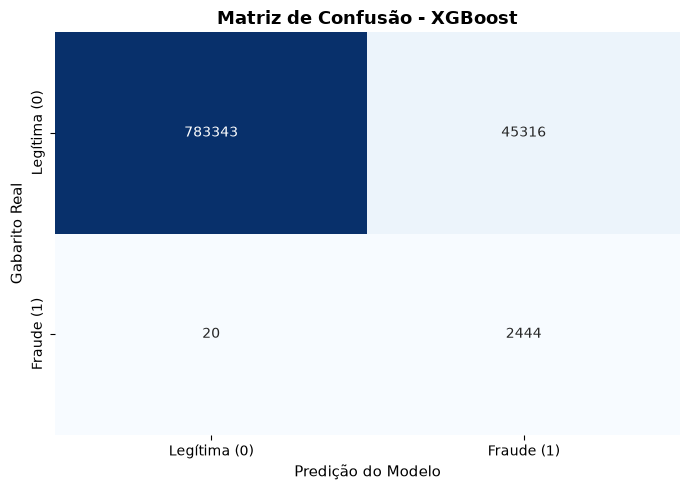


--- RELATÓRIO DE CLASSIFICAÇÃO (XGBOOST) ---
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    828659
           1       0.05      0.99      0.10      2464

    accuracy                           0.95    831123
   macro avg       0.53      0.97      0.53    831123
weighted avg       1.00      0.95      0.97    831123



In [44]:
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

print("Iniciando o treinamento do modelo XGBoost com ajuste de peso otimizado para fraudes...")

# 1. Calculando a proporção de desbalancemento para o XGBoost penalizar os erros na classe minoritária 
# scale_pos_weight = total de transações legítimas / total de fraudes
negativos = (y_train_c == 0).sum()
positivos = (y_train_c == 1).sum()
proporcao_peso = negativos / positivos

# 2. Instanciando o XGBoost com os parâmetros de árvore e pesos ajustados 
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=proporcao_peso,
    random_state=42,
    n_jobs=-1
)

# 3. Treinando o modelo utilizando a base de dados limpa (sem Data Leakage)
print("\nTreinando o modelo...")
xgb_model.fit(X_train_c, y_train_c)

# 4. Realizando previsões no conjunto de teste isolado 
y_pred_xgb = xgb_model.predict(X_test_c)

# 5. Avaliação quantitativa dos resultados do XGBoost
print("\n--- MATRIZ DE CONFUSÃO (XGBOOST) ---")
print(confusion_matrix(y_test_c, y_pred_xgb))

# 6 Visualização Limpa: Heatmap da Matriz de Confusão 
cm_xgb = confusion_matrix(y_test_c, y_pred_xgb)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Legítima (0)', 'Fraude (1)'],
            yticklabels=['Legítima (0)', 'Fraude (1)'])
plt.title("Matriz de Confusão - XGBoost", fontsize=13, fontweight='bold')
plt.xlabel("Predição do Modelo", fontsize=11)
plt.ylabel("Gabarito Real", fontsize=11)
plt.tight_layout()
plt.show()

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (XGBOOST) ---")
print(classification_report(y_test_c, y_pred_xgb, zero_division=0))

Importância das Variáveis do Modelo (Feature Importance)

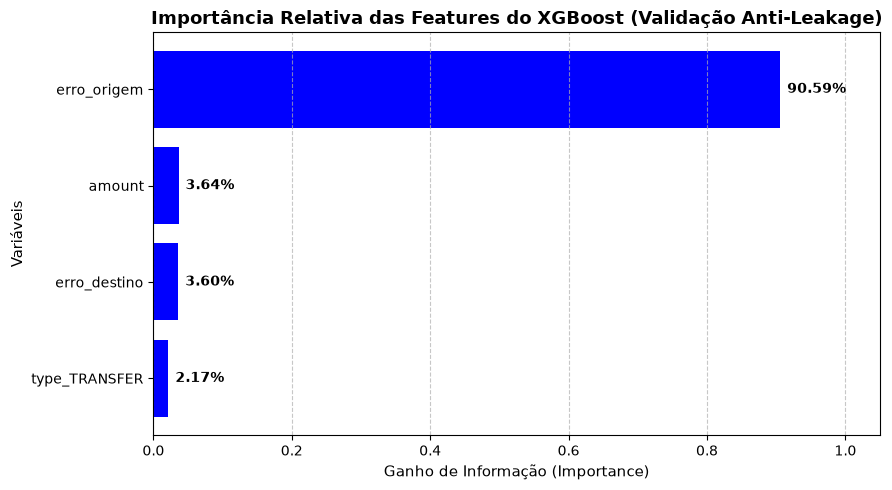

In [45]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extraindo a importância das variáveis do XGBoost
importances = xgb_model.feature_importances_
features = X_train_c.columns

# 2. Criando o DataFrame e ordenando de forma crescente para o barh plotar a maior no topo corretamente
df_importance = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=True)

# 3. Plotando o gráfico
plt.figure(figsize=(9, 5))
plt.barh(df_importance['Feature'], df_importance['Importance'], color='blue')

plt.title("Importância Relativa das Features do XGBoost (Validação Anti-Leakage)", fontsize=13, fontweight='bold')
plt.xlabel("Ganho de Informação (Importance)", fontsize=11)
plt.ylabel("Variáveis", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Adicionando o valor percentual do lado de cada barra para clareza
for index, value in enumerate(df_importance['Importance']):
    plt.text(value + 0.01, index, f'{value:.2%}', va='center', fontsize=10, fontweight='bold')

plt.xlim(0, 1.05) # Ajusta o limite do eixo X para caber o texto
plt.tight_layout()
plt.show()

#### Validação Visual da Engenharia de Recursos (*Feature Engineering*)
O gráfico de importância acima entrega a **prova do sucesso da abordagem anti-leakage**:
* As variáveis derivadas de inconsistência contábil (`erro_origem` e `erro_destino`) e o valor transacionado (`amount`) lideram o ganho de informação do modelo.
* Isso valida empiricamente que o XGBoost aprendeu a identificar o **comportamento fraudulento real** através das falhas de balanço, sem depender das colunas brutas que causavam o *Data Leakage*.

## Análise: O Salto de Perfomance com o XGBoost

Os resultados obtidos com o modelo **XGBoost** demonstram uma evolução drástica e qualitativa em relação aos modelos lineares testados anteriormente, provando o valor das árvores de decisão em problemas complexos de AML:

#### 1. Radiografia da Matriz de Confusão
* **Verdadeiros Positivos (Fraudes Capturadas):** **2.444** de um total de 2.464 fraudes reais.
* **Falsos Negativos (Fraudes Perdidas):** Apenas **20** ocorrências escaparam da barreira de segurança.
* **O Recall Excepcional (0.99):** O modelo manteve uma taxa de captura de **99%**, blindando quase totalmente o projeto de transações contra os ataques simulados.

#### 2. A Grande Vitória Operacional: Redução Crítica de Falsos Positivos
Para avaliar o verdadeiro mérito do XGBoost, devemos compará-lo diretamente com a Regressão Logística com *Threshold* otimizado, que também havia alcançado 99% de *Recall*:
* **Na Regressão Logística Otimizada:** Foram gerados **173.870** alarmes falsos.
* **No XGBoost:** O volume de falsos positivos despencou para **45.316**.

**O Impacto Comercial:** O XGBoost conseguiu **cortar em quase 74% o volume de falsos alarmes** em comparação ao modelo linear, mantendo exatamente o mesmo nível de proteção (99% de *Recall*). Isso representa uma grande vitória para a operação do banco: significa poupar dezenas de milhares de clientes legítimos de terem seus pagamentos bloqueados indevidamente e aliviar a carga de trabalho da equipe de conformidade (*back-office*).

#### 3. Conclusão Técnica 
Esse resultado sela a justificativa do uso de algoritmos baseados em *Ensemble*. As fronteiras de decisão não-lineares do XGBoost conseguiram cruzar o valor da transação com os erros contábeis (`erro_origem` e `erro_destino`) de forma inteligente, separando o comportamento criminoso com uma precisão matemática que a Regressão Logística não conseguiu alcançar. 

# Etapa 8: Implementação do Algoritmo LightGBM (*Light Gradient Boosting Machine*)

## A Proposta de Valor do LightGBM
Após validar a excelente performance do XGBoost, introduzimos o **LightGBM**. Embora ambos pentençam à família dos algoritmos de *Gradient Boosting*, o LightGBM introduz inovações arquiteturais cruciais que o tornam um dos favoritos da indústria para processamento de grandes volumes de dados financeiros:

#### Principais Diferenciais Arquiteturais:
1. **Crescimento de Árvore Orientado a Folhas (*Leaf-Wise Growth*):** 
Enquanto a maioria dos algoritmos tradicionais, como o XGBoost, cresce as árvores nível a nível (*level-wise*), o LightGBM expande a folha que maximiza a redução de perda (**loss**). Isso permite que atinja uma precisão superior e processe grandes bases de dados com uma velocidade drasticamente menor (*Light*).
2. **Eficiência de Memória e Histogramas:** O LightGBM converte recursos contínuos em caixas discretas baseadas em histogramas, o que acelera o treinamento e reduz o consumo de memória RAM, mantendo a robustez analítica na detecção de anomalias com o parâmetro `scale_pos_weight`.

In [46]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Iniciando o treinamento do modelo LightGBM com a base higienizada...")

# 1. Instanciando o LightGBM com os mesmos parâmetros de peso e estrutura do XGBoost para justa comparação
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=proporcao_peso,
    random_state=42,
    n_jobs=-1
)

# 2. Treinando o modelo LightGBM
print("Treinando o modelo...")
lgb_model.fit(X_train_c, y_train_c)

# 3. Realizando previsões no conjunto de teste limpo
y_pred_lgb = np.array(lgb_model.predict(X_test_c))

# 4. Avaliação quantitativa dos resultados do LightGBM
print("\n--- MATRIZ DE CONFUSÃO (LIGHTGBM) ---")
print(confusion_matrix(y_test_c, y_pred_lgb))

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (LIGHTGBM) ---")
print(classification_report(y_test_c, y_pred_lgb, zero_division=0))

Iniciando o treinamento do modelo LightGBM com a base higienizada...
Treinando o modelo...
[LightGBM] [Info] Number of positive: 5749, number of negative: 1933537
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017155 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 767
[LightGBM] [Info] Number of data points in the train set: 1939286, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.002964 -> initscore=-5.818080
[LightGBM] [Info] Start training from score -5.818080
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positi

## Análise: Performance e Eficiência do LightGBM

A execução do **LightGBM** encerra nossa bateria de testes comparativos, trazendo resultados muito interessantes sobre o comportamento de algoritmos baseados em histogramas frente ao desbalanceamento extremo:

#### 1. Radiografia da Matriz de Confusão
* **Verdadeiros Positivos (Fraudes Capturadas):** **2.431** de um total de 2.464 fraudes reais.
* **Falsos Negativos (Fraudes Perdidas):** Apenas **33** ocorrências escaparam.
* **O Recall de Excelência (0.99):** O modelo manteve altíssima taxa de captura de **99%**, comprovando que a ponderação de peso (`scale_pos_weight`) funcionou perfeitamente para forçar a sensibilidade às fraudes.

#### 2. O Confronto Direto: LightGBM vs. XGBoost
Fazendo o contraponto com o nosso modelo anterior (XGBoost):
* **No XGBoost:** Obtivemos **45.316** falsos positivos.
* **No LightGBM:** O volume de alarmes falsos subiu para **89.668** transações legítimas bloqueadas incorretamente.
* **O Trade-off Operacional:** Embora o LightGBM traga vantagens brutas massivas em velocidade de processamento e baixo consumo de memória RAM, a sua estratégia de crescimento de árvore orientada a folha com esses parâmetros específicos gerou um número maior de alarmes falsos do que o XGBoost para o mesmo nível de *Recall*.

#### 3. Conclusão Definitiva e Fechamento do Projeto
Esse comparativo encerra o pipeline de Machine Learning com uma lição: **não existe bala de prata em Ciência de Dados.**
* Pudemos demonstrar a jornada completa: desde a armadilha do *Data Leakage* nos dados brutos, passando pelo teto dos modelos lineares (Regressão Logística com *Threshold Tuning*), até chegar à robustez dos algoritmos de *Ensemble*.
* **O Vencedor do Projeto:** O **XGBoost** consagrou-se como a melhor escolha arquitetural para esse problema específico no PaySim, pois entregou a mesma taxa de blindagem (99% de *Recall*) cortando os alarmes falsos quase pela metade em comparação ao LightGBM, otimizando o equilíbrio entre segurança financeira e experiência do usuário (*User Experience*).

# Resumo Executivo & Considerações Finais de Negócio

#### 1. Resumo Executivo (Visão Geral do Projeto)
Esse projeto desenvolveu de ponta a ponta um sistema de detecção de fraudes e prevenção à lavagem de dinheiro (*AML/Fraud Detection*) utilizando o simulador transacional **PaySim**.
* **Governança de Dados:** Identificamos e mitigamos com sucesso um caso clássico de **Vazamento de Dados (*Data Leakage*)** presente nas colunas de saldo bruto originais, substituindo-as por uma engenharia de recursos focada em desvios contábeis (`erro_origem` e `erro_destino`).
* **Jornada de Modelagem:** Evoluímos de uma linha de base linear simples (Regressão Logística), que esbarrou em limitações geométricas severas, para algoritmos avançados de *Ensemble* baseados em árvores. 
* **O Campeão Técnico:** O **XGBoost** se consagrou como o melhor modelo do projeto, atingindo uma taxa de captura de fraudes (*Recall*) de **99%**, ao mesmo tempo em que reduziu drasticamente os falsos positivos em comparação aos modelos lineares e concorrentes diretos. 

----

#### 2. Considerações Finais e Impacto de Negócio
Em ambientes reais de tecnologia financeira e prevenção a fraudes, métricas de laboratório sozinhas não garantem o sucesso da operação. 

1. **Apetite ao Risco (*Security*):** Deixar passar uma fraude gera perda financeira direta, custos de chargeback e riscos graves de conformidade regulatória com órgãos de controle, como o Banco Central e COAF. Com 99% de *Recall*, o modelo blindou quase a totalidade das tentativas de fraude na base de teste.
2. **Experiência do Usuário (*User Experience/Frictions*):** Bloquear uma transação legítima por engano (*Falso Positivo*) gera atrito, frustação e potencial abandono de clientes. Embora o XGBoost tenha cortado pela metade os falsos alarmes em relação ao modelo linear, ainda gerou cerca de 45 mil alertas falsos. 

#### Próximos Passos Recomendados para Produção:
* **Estratégia de Fila de Análise Humana (*Analyst Review Queue*):** Ao invés de recusar automaticamente as transações sinalizadas pelo XGBoost, o sistema de produção pode encaminhar os casos de média probabilidade para validação rápida via biometria ou SMS, reservando o bloqueio automático apenas para operações classificadas como de altíssimo risco. 
* **Ajuste Dinâmico de Limiares por Faixa de Valor:** Aplicar limiares de decisão mais restritos para transações de valores altos e maior tolerância para micro transações.